In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "online_retail_II_limpio.csv",
    dtype={
        "Invoice": str,
        "StockCode": str
    },
    low_memory=False
)

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Dimensiones:", df.shape)
print(df.head())


Dimensiones: (1007913, 9)
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

          InvoiceDate  Price  Customer ID         Country  TotalAmount  
0 2009-12-01 07:45:00   6.95      13085.0  United Kingdom         83.4  
1 2009-12-01 07:45:00   6.75      13085.0  United Kingdom         81.0  
2 2009-12-01 07:45:00   6.75      13085.0  United Kingdom         81.0  
3 2009-12-01 07:45:00   2.10      13085.0  United Kingdom        100.8  
4 2009-12-01 07:45:00   1.25      13085.0  United Kingdom         30.0  


In [3]:
# ============================================================
# PARTE 1: CREAR BASE A NIVEL CLIENTE
# ============================================================

# Solo clientes identificados
df_clientes_base = df.dropna(
    subset=["Customer ID"]
).copy()

# Fecha de referencia:
# un día después de la última compra registrada
fecha_referencia = (
    df_clientes_base["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

# Resumir todas las compras de cada cliente
clientes = (
    df_clientes_base
    .groupby("Customer ID")
    .agg(
        Ultima_compra=("InvoiceDate", "max"),
        Frecuencia=("Invoice", "nunique"),
        Cantidad_total=("Quantity", "sum"),
        Gasto_total=("TotalAmount", "sum")
    )
    .reset_index()
)

# Calcular recencia
clientes["Recencia"] = (
    fecha_referencia
    - clientes["Ultima_compra"]
).dt.days

# Definir Premium como el 20 % con mayor gasto total
umbral_premium = clientes["Gasto_total"].quantile(0.80)

clientes["Categoria"] = np.where(
    clientes["Gasto_total"] >= umbral_premium,
    "Premium",
    "Normal"
)

print("Clientes totales:", len(clientes))
print(f"Umbral Premium: £{umbral_premium:,.2f}")

print("\nDistribución:")
print(clientes["Categoria"].value_counts())

print("\nPrimeros clientes:")
print(clientes.head())

Clientes totales: 5878
Umbral Premium: £2,910.08

Distribución:
Categoria
Normal     4702
Premium    1176
Name: count, dtype: int64

Primeros clientes:
   Customer ID       Ultima_compra  Frecuencia  Cantidad_total  Gasto_total  \
0      12346.0 2011-01-18 10:01:00          12           74285     77556.46   
1      12347.0 2011-12-07 15:52:00           8            2967      4921.53   
2      12348.0 2011-09-25 13:13:00           5            2714      2019.40   
3      12349.0 2011-11-21 09:51:00           4            1624      4428.69   
4      12350.0 2011-02-02 16:01:00           1             197       334.40   

   Recencia Categoria  
0       326   Premium  
1         2   Premium  
2        75    Normal  
3        19   Premium  
4       310    Normal  


In [4]:
# ============================================================
# PARTE 1: MODELO DE CLASIFICACIÓN
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Variables que usará el modelo
X = clientes[
    [
        "Recencia",
        "Frecuencia",
        "Cantidad_total"
    ]
]

# Variable objetivo
y = clientes["Categoria"]

# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Clientes para entrenamiento:", len(X_train))
print("Clientes para prueba:", len(X_test))

Clientes para entrenamiento: 4702
Clientes para prueba: 1176


In [6]:
# Crear modelo Random Forest
modelo_clasificacion = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Entrenar el modelo
modelo_clasificacion.fit(
    X_train,
    y_train
)

# Hacer predicciones
y_pred = modelo_clasificacion.predict(X_test)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [7]:
# ============================================================
# EVALUACIÓN DEL MODELO
# ============================================================

accuracy = accuracy_score(
    y_test,
    y_pred
)

print(f"Accuracy: {accuracy:.4f}")

print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(
    classification_report(
        y_test,
        y_pred
    )
)

print("\n=== MATRIZ DE CONFUSIÓN ===")
print(
    confusion_matrix(
        y_test,
        y_pred,
        labels=["Normal", "Premium"]
    )
)

Accuracy: 0.9354

=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

      Normal       0.96      0.96      0.96       941
     Premium       0.84      0.84      0.84       235

    accuracy                           0.94      1176
   macro avg       0.90      0.90      0.90      1176
weighted avg       0.94      0.94      0.94      1176


=== MATRIZ DE CONFUSIÓN ===
[[902  39]
 [ 37 198]]


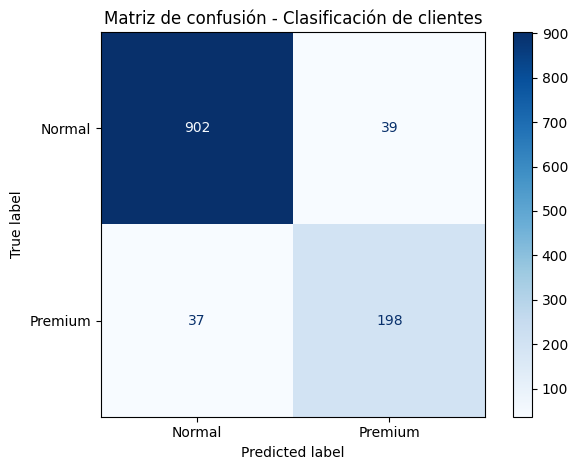

In [8]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Normal", "Premium"],
    cmap="Blues"
)

plt.title("Matriz de confusión - Clasificación de clientes")
plt.tight_layout()
plt.show()

In [10]:
importancia_variables = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": modelo_clasificacion.feature_importances_
}).sort_values(
    "Importancia",
    ascending=False
)

print("=== IMPORTANCIA DE VARIABLES ===")
print(importancia_variables)

=== IMPORTANCIA DE VARIABLES ===
         Variable  Importancia
2  Cantidad_total     0.546164
1      Frecuencia     0.309211
0        Recencia     0.144625


In [11]:
# ============================================================
# PARTE 2: SEGMENTACIÓN DE CLIENTES
# PREPARACIÓN DE VARIABLES
# ============================================================

from sklearn.preprocessing import StandardScaler

# Variables para clustering
X_cluster = clientes[
    [
        "Recencia",
        "Frecuencia",
        "Gasto_total"
    ]
].copy()

# Escalar las variables
scaler = StandardScaler()

X_cluster_scaled = scaler.fit_transform(
    X_cluster
)

print("Dimensiones para clustering:")
print(X_cluster_scaled.shape)

Dimensiones para clustering:
(5878, 3)


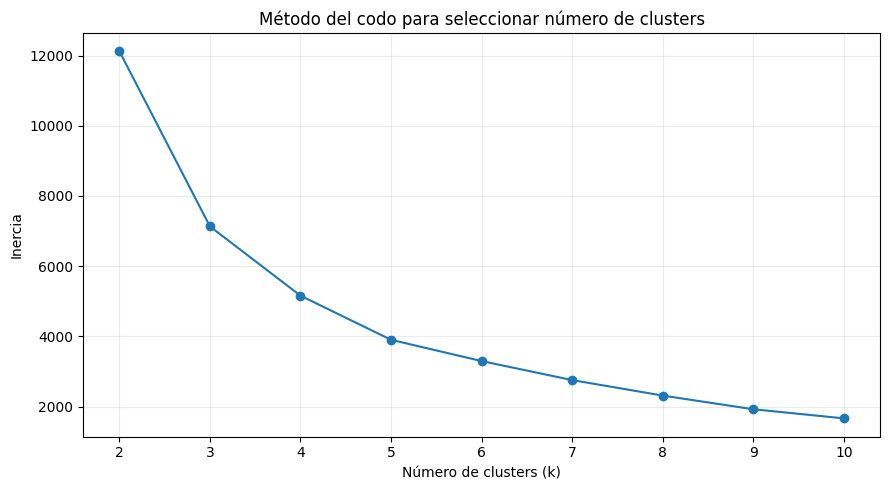

In [12]:
# ============================================================
# PARTE 2: MÉTODO DEL CODO PARA K-MEANS
# ============================================================

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inercias = []

rangos_k = range(2, 11)

for k in rangos_k:
    modelo_kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo_kmeans.fit(X_cluster_scaled)

    inercias.append(
        modelo_kmeans.inertia_
    )

plt.figure(figsize=(9, 5))

plt.plot(
    list(rangos_k),
    inercias,
    marker="o"
)

plt.title("Método del codo para seleccionar número de clusters")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# VALIDACIÓN DEL NÚMERO DE CLUSTERS: SILHOUETTE SCORE
# ============================================================

from sklearn.metrics import silhouette_score

resultados_silhouette = []

for k in range(2, 7):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(
        X_cluster_scaled
    )

    score = silhouette_score(
        X_cluster_scaled,
        etiquetas
    )

    resultados_silhouette.append({
        "k": k,
        "Silhouette": score
    })

tabla_silhouette = pd.DataFrame(
    resultados_silhouette
)

print("=== SILHOUETTE SCORE ===")
print(
    tabla_silhouette
    .round(4)
    .to_string(index=False)
)

=== SILHOUETTE SCORE ===
 k  Silhouette
 2      0.9236
 3      0.5827
 4      0.5913
 5      0.6030
 6      0.5495


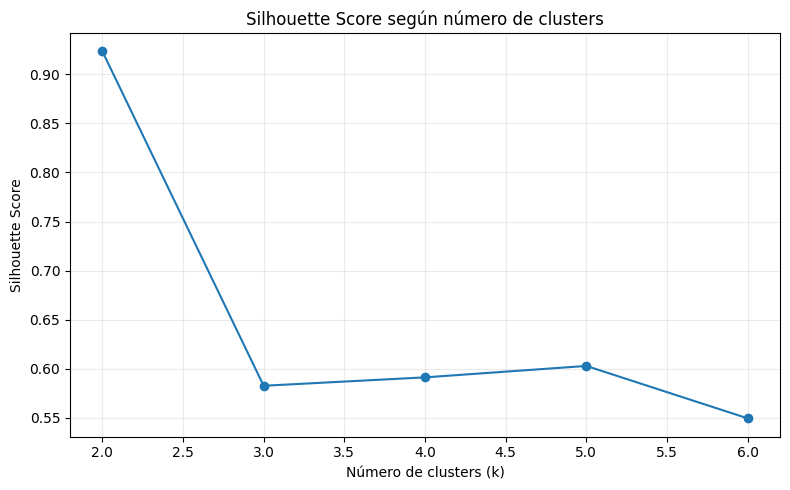

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(
    tabla_silhouette["k"],
    tabla_silhouette["Silhouette"],
    marker="o"
)

plt.title("Silhouette Score según número de clusters")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [15]:
# ============================================================
# COMPROBAR QUÉ OCURRE CON K = 2
# ============================================================

kmeans_2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clientes["Cluster_k2"] = kmeans_2.fit_predict(
    X_cluster_scaled
)

print("=== TAMAÑO DE LOS CLUSTERS CON K = 2 ===")

print(
    clientes["Cluster_k2"]
    .value_counts()
    .sort_index()
)

=== TAMAÑO DE LOS CLUSTERS CON K = 2 ===
Cluster_k2
0      18
1    5860
Name: count, dtype: int64


In [16]:
perfil_k2 = (
    clientes
    .groupby("Cluster_k2")
    .agg(
        Clientes=("Customer ID", "count"),
        Recencia_media=("Recencia", "mean"),
        Frecuencia_media=("Frecuencia", "mean"),
        Gasto_medio=("Gasto_total", "mean")
    )
    .round(2)
)

print("\n=== PERFIL DE LOS CLUSTERS K = 2 ===")
print(perfil_k2)


=== PERFIL DE LOS CLUSTERS K = 2 ===
            Clientes  Recencia_media  Frecuencia_media  Gasto_medio
Cluster_k2                                                         
0                 18           25.44            162.56    185704.03
1               5860          201.87              5.81      2394.56


In [17]:
# ============================================================
# TRANSFORMACIÓN LOGARÍTMICA PARA REDUCIR ASIMETRÍA
# ============================================================

X_cluster_log = clientes[
    [
        "Recencia",
        "Frecuencia",
        "Gasto_total"
    ]
].copy()

# Transformación logarítmica
X_cluster_log["Recencia"] = np.log1p(
    X_cluster_log["Recencia"]
)

X_cluster_log["Frecuencia"] = np.log1p(
    X_cluster_log["Frecuencia"]
)

X_cluster_log["Gasto_total"] = np.log1p(
    X_cluster_log["Gasto_total"]
)

# Escalar nuevamente
scaler_log = StandardScaler()

X_cluster_log_scaled = scaler_log.fit_transform(
    X_cluster_log
)

print("Dimensiones después de transformación:")
print(X_cluster_log_scaled.shape)

Dimensiones después de transformación:
(5878, 3)


In [18]:
# ============================================================
# SILHOUETTE DESPUÉS DE TRANSFORMACIÓN LOG
# ============================================================

resultados_log = []

for k in range(2, 7):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(
        X_cluster_log_scaled
    )

    score = silhouette_score(
        X_cluster_log_scaled,
        etiquetas
    )

    resultados_log.append({
        "k": k,
        "Silhouette": score
    })

tabla_silhouette_log = pd.DataFrame(
    resultados_log
)

print("=== SILHOUETTE DESPUÉS DE TRANSFORMACIÓN LOG ===")

print(
    tabla_silhouette_log
    .round(4)
    .to_string(index=False)
)

=== SILHOUETTE DESPUÉS DE TRANSFORMACIÓN LOG ===
 k  Silhouette
 2      0.4386
 3      0.3477
 4      0.3650
 5      0.3425
 6      0.3348


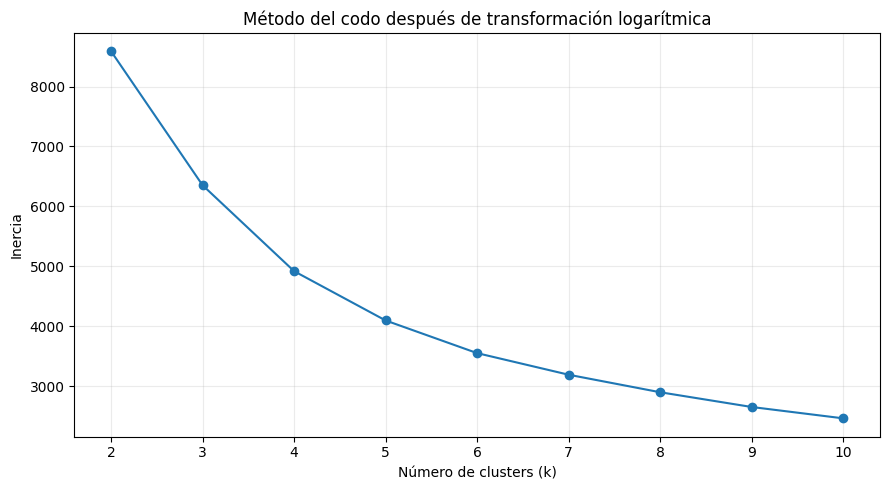

In [19]:
inercias_log = []

for k in range(2, 11):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(
        X_cluster_log_scaled
    )

    inercias_log.append(
        modelo.inertia_
    )

plt.figure(figsize=(9, 5))

plt.plot(
    range(2, 11),
    inercias_log,
    marker="o"
)

plt.title(
    "Método del codo después de transformación logarítmica"
)

plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [20]:
print(
    tabla_silhouette_log
    .round(4)
    .to_string(index=False)
)


 k  Silhouette
 2      0.4386
 3      0.3477
 4      0.3650
 5      0.3425
 6      0.3348


In [21]:
# ============================================================
# K-MEANS DEFINITIVO CON 4 CLUSTERS
# ============================================================

kmeans_final = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clientes["Cluster_KMeans"] = kmeans_final.fit_predict(
    X_cluster_log_scaled
)

print("=== TAMAÑO DE LOS CLUSTERS K-MEANS ===")

print(
    clientes["Cluster_KMeans"]
    .value_counts()
    .sort_index()
)

=== TAMAÑO DE LOS CLUSTERS K-MEANS ===
Cluster_KMeans
0    1973
1    1250
2    1196
3    1459
Name: count, dtype: int64


In [22]:
# ============================================================
# PERFIL DE LOS CLUSTERS
# ============================================================

perfil_kmeans = (
    clientes
    .groupby("Cluster_KMeans")
    .agg(
        Clientes=("Customer ID", "count"),
        Recencia_media=("Recencia", "mean"),
        Frecuencia_media=("Frecuencia", "mean"),
        Cantidad_media=("Cantidad_total", "mean"),
        Gasto_medio=("Gasto_total", "mean")
    )
    .round(2)
)

print("=== PERFIL DE LOS CLUSTERS K-MEANS ===")
print(perfil_kmeans)

=== PERFIL DE LOS CLUSTERS K-MEANS ===
                Clientes  Recencia_media  Frecuencia_media  Cantidad_media  \
Cluster_KMeans                                                               
0                   1973          394.95              1.38          187.60   
1                   1250           28.30              3.05          530.97   
2                   1196           27.71             19.28         6336.26   
3                   1459          230.07              5.06         1303.59   

                Gasto_medio  
Cluster_KMeans               
0                    317.08  
1                    857.49  
2                  10731.16  
3                   1948.50  


In [23]:
# ============================================================
# ASIGNAR NOMBRES A LOS SEGMENTOS K-MEANS
# ============================================================

nombres_clusters = {
    0: "Inactivos - Bajo valor",
    1: "Recientes ocasionales",
    2: "Alto valor",
    3: "Intermedios - En riesgo"
}

clientes["Segmento_KMeans"] = (
    clientes["Cluster_KMeans"]
    .map(nombres_clusters)
)

print(
    clientes[
        [
            "Customer ID",
            "Recencia",
            "Frecuencia",
            "Gasto_total",
            "Segmento_KMeans"
        ]
    ]
    .head(10)
)

   Customer ID  Recencia  Frecuencia  Gasto_total          Segmento_KMeans
0      12346.0       326          12     77556.46               Alto valor
1      12347.0         2           8      4921.53               Alto valor
2      12348.0        75           5      2019.40  Intermedios - En riesgo
3      12349.0        19           4      4428.69    Recientes ocasionales
4      12350.0       310           1       334.40   Inactivos - Bajo valor
5      12351.0       375           1       300.93   Inactivos - Bajo valor
6      12352.0        36          10      2849.84               Alto valor
7      12353.0       204           2       406.76   Inactivos - Bajo valor
8      12354.0       232           1      1079.40   Inactivos - Bajo valor
9      12355.0       214           2       947.61  Intermedios - En riesgo


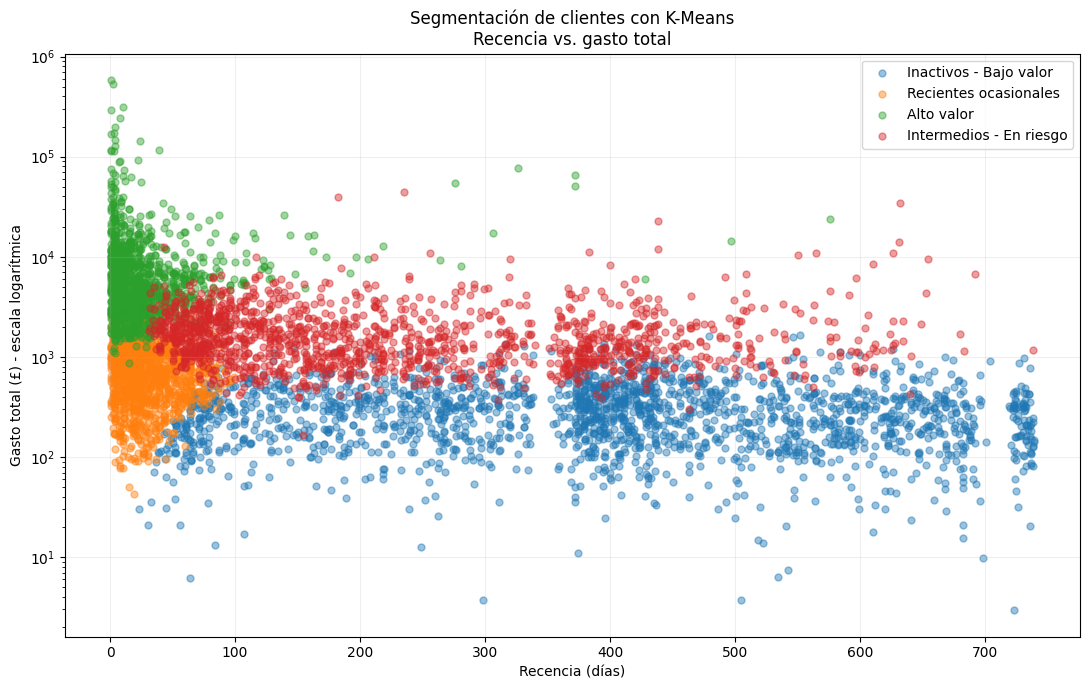

In [24]:
# ============================================================
# VISUALIZACIÓN DE LOS SEGMENTOS K-MEANS
# ============================================================

plt.figure(figsize=(11, 7))

for cluster in sorted(clientes["Cluster_KMeans"].unique()):

    datos = clientes[
        clientes["Cluster_KMeans"] == cluster
    ]

    plt.scatter(
        datos["Recencia"],
        datos["Gasto_total"],
        alpha=0.45,
        s=25,
        label=nombres_clusters[cluster]
    )

plt.yscale("log")

plt.title(
    "Segmentación de clientes con K-Means\n"
    "Recencia vs. gasto total"
)

plt.xlabel("Recencia (días)")
plt.ylabel("Gasto total (£) - escala logarítmica")

plt.legend()
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()

In [25]:
# ============================================================
# MEAN SHIFT
# ============================================================

from sklearn.cluster import MeanShift, estimate_bandwidth

# Estimar automáticamente el bandwidth
bandwidth = estimate_bandwidth(
    X_cluster_log_scaled,
    quantile=0.20,
    n_samples=2000,
    random_state=42
)

print("Bandwidth estimado:", round(bandwidth, 4))

Bandwidth estimado: 1.2334


In [26]:
# ============================================================
# ENTRENAR MEAN SHIFT
# ============================================================

mean_shift = MeanShift(
    bandwidth=bandwidth,
    bin_seeding=True
)

clientes["Cluster_MeanShift"] = mean_shift.fit_predict(
    X_cluster_log_scaled
)

numero_clusters_ms = clientes["Cluster_MeanShift"].nunique()

print("Número de clusters encontrados por Mean Shift:")
print(numero_clusters_ms)

print("\nTamaño de los clusters:")
print(
    clientes["Cluster_MeanShift"]
    .value_counts()
    .sort_index()
)

Número de clusters encontrados por Mean Shift:
3

Tamaño de los clusters:
Cluster_MeanShift
0    5269
1     263
2     346
Name: count, dtype: int64


In [27]:
# ============================================================
# PERFIL DE CLUSTERS - MEAN SHIFT
# ============================================================

perfil_meanshift = (
    clientes
    .groupby("Cluster_MeanShift")
    .agg(
        Clientes=("Customer ID", "count"),
        Recencia_media=("Recencia", "mean"),
        Frecuencia_media=("Frecuencia", "mean"),
        Cantidad_media=("Cantidad_total", "mean"),
        Gasto_medio=("Gasto_total", "mean")
    )
    .round(2)
)

print("=== PERFIL DE LOS CLUSTERS MEAN SHIFT ===")
print(perfil_meanshift)

=== PERFIL DE LOS CLUSTERS MEAN SHIFT ===
                   Clientes  Recencia_media  Frecuencia_media  Cantidad_media  \
Cluster_MeanShift                                                               
0                      5269          221.78              3.85          805.33   
1                       263           44.95             42.50        16633.10   
2                       346            8.86             15.99         5480.21   

                   Gasto_medio  
Cluster_MeanShift               
0                      1260.53  
1                     28329.15  
2                      9487.00  


In [28]:
# ============================================================
# SILHOUETTE DE MEAN SHIFT
# ============================================================

if numero_clusters_ms > 1:
    silhouette_ms = silhouette_score(
        X_cluster_log_scaled,
        clientes["Cluster_MeanShift"]
    )

    print(
        "Silhouette Mean Shift:",
        round(silhouette_ms, 4)
    )
else:
    print("Mean Shift encontró un solo cluster.")

Silhouette Mean Shift: 0.3519


In [29]:
# ============================================================
# COMPARACIÓN FINAL: K-MEANS VS MEAN SHIFT
# ============================================================

comparacion_clustering = pd.DataFrame({
    "Algoritmo": [
        "K-Means",
        "Mean Shift"
    ],
    "Numero_clusters": [
        4,
        numero_clusters_ms
    ],
    "Silhouette": [
        silhouette_score(
            X_cluster_log_scaled,
            clientes["Cluster_KMeans"]
        ),
        silhouette_ms
    ]
})

print("=== COMPARACIÓN DE ALGORITMOS DE CLUSTERING ===")

print(
    comparacion_clustering
    .round(4)
    .to_string(index=False)
)

=== COMPARACIÓN DE ALGORITMOS DE CLUSTERING ===
 Algoritmo  Numero_clusters  Silhouette
   K-Means                4      0.3650
Mean Shift                3      0.3519


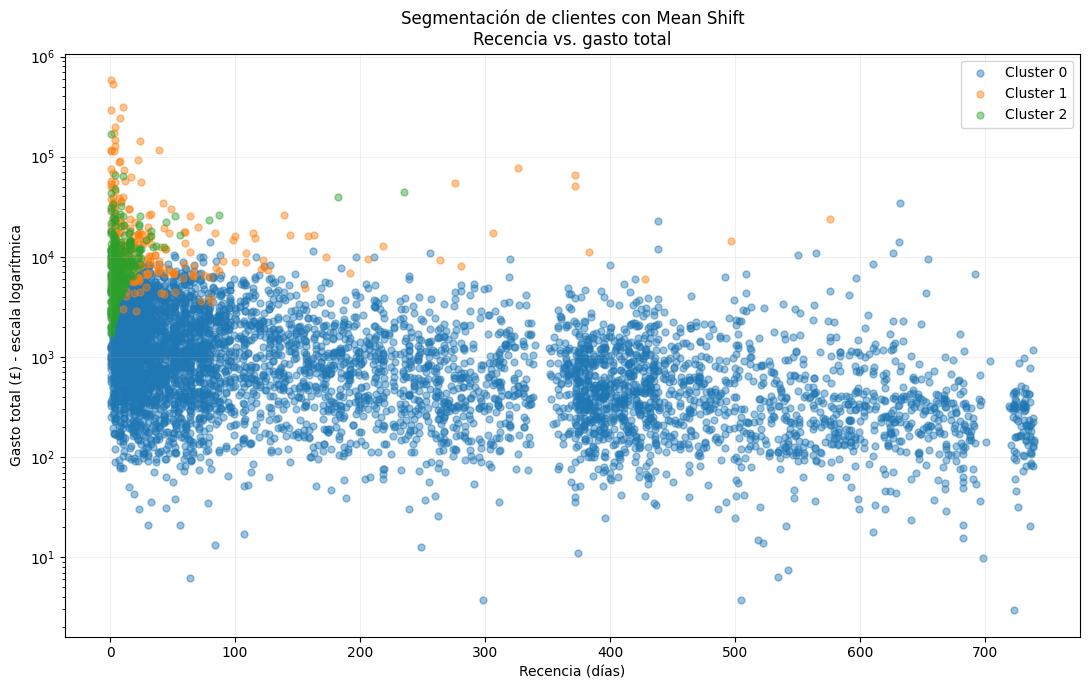

In [30]:
# ============================================================
# VISUALIZACIÓN MEAN SHIFT
# ============================================================

plt.figure(figsize=(11, 7))

for cluster in sorted(
    clientes["Cluster_MeanShift"].unique()
):

    datos = clientes[
        clientes["Cluster_MeanShift"] == cluster
    ]

    plt.scatter(
        datos["Recencia"],
        datos["Gasto_total"],
        alpha=0.45,
        s=25,
        label=f"Cluster {cluster}"
    )

plt.yscale("log")

plt.title(
    "Segmentación de clientes con Mean Shift\n"
    "Recencia vs. gasto total"
)

plt.xlabel("Recencia (días)")
plt.ylabel("Gasto total (£) - escala logarítmica")

plt.legend()
plt.grid(alpha=0.20)
plt.tight_layout()
plt.show()

In [31]:
# ============================================================
# PARTE 3: PREDICCIÓN DE VENTAS
# CREAR SERIE DE VENTAS DIARIAS
# ============================================================

# Asegurar que InvoiceDate sea fecha
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Crear fecha sin la hora
df["Fecha"] = df["InvoiceDate"].dt.date

# Sumar todas las ventas de cada día
ventas_diarias = (
    df
    .groupby("Fecha")["TotalAmount"]
    .sum()
    .reset_index()
)

# Convertir nuevamente a datetime
ventas_diarias["Fecha"] = pd.to_datetime(
    ventas_diarias["Fecha"]
)

# Orden cronológico
ventas_diarias = ventas_diarias.sort_values(
    "Fecha"
).reset_index(drop=True)

print("=== VENTAS DIARIAS ===")
print(ventas_diarias.head(10))

print("\nPeriodo:")
print(
    ventas_diarias["Fecha"].min(),
    "hasta",
    ventas_diarias["Fecha"].max()
)

print("\nNúmero de días con ventas:")
print(len(ventas_diarias))

=== VENTAS DIARIAS ===
       Fecha  TotalAmount
0 2009-12-01     54351.23
1 2009-12-02     63172.58
2 2009-12-03     73972.45
3 2009-12-04     40582.32
4 2009-12-05      9803.05
5 2009-12-06     24423.02
6 2009-12-07     44916.21
7 2009-12-08     49476.23
8 2009-12-09     40265.66
9 2009-12-10     44233.96

Periodo:
2009-12-01 00:00:00 hasta 2011-12-09 00:00:00

Número de días con ventas:
604


In [32]:
# ============================================================
# CREACIÓN DE CARACTERÍSTICAS PARA PREDICCIÓN
# ============================================================

ventas_diarias["Anio"] = ventas_diarias["Fecha"].dt.year
ventas_diarias["Mes"] = ventas_diarias["Fecha"].dt.month
ventas_diarias["Dia_semana"] = ventas_diarias["Fecha"].dt.dayofweek
ventas_diarias["Dia_mes"] = ventas_diarias["Fecha"].dt.day

# Ventas del día anterior
ventas_diarias["Lag_1"] = (
    ventas_diarias["TotalAmount"]
    .shift(1)
)

# Ventas de hace 7 días
ventas_diarias["Lag_7"] = (
    ventas_diarias["TotalAmount"]
    .shift(7)
)

# Promedio de los 7 días anteriores
ventas_diarias["Media_7"] = (
    ventas_diarias["TotalAmount"]
    .shift(1)
    .rolling(7)
    .mean()
)

# Eliminar primeras filas donde todavía no existen rezagos
ventas_modelo = (
    ventas_diarias
    .dropna()
    .reset_index(drop=True)
)

print("=== DATOS PREPARADOS PARA EL MODELO ===")

print(
    ventas_modelo[
        [
            "Fecha",
            "TotalAmount",
            "Mes",
            "Dia_semana",
            "Lag_1",
            "Lag_7",
            "Media_7"
        ]
    ]
    .head(10)
)

=== DATOS PREPARADOS PARA EL MODELO ===
       Fecha  TotalAmount  Mes  Dia_semana     Lag_1     Lag_7       Media_7
0 2009-12-08     49476.23   12           1  44916.21  54351.23  44460.122857
1 2009-12-09     40265.66   12           2  49476.23  63172.58  43763.694286
2 2009-12-10     44233.96   12           3  40265.66  73972.45  40491.277143
3 2009-12-11     39447.89   12           4  44233.96  40582.32  36242.921429
4 2009-12-13     22176.46   12           6  39447.89   9803.05  36080.860000
5 2009-12-14     73174.39   12           0  22176.46  24423.02  37848.490000
6 2009-12-15     50262.29   12           1  73174.39  44916.21  44812.971429
7 2009-12-16     52545.55   12           2  50262.29  49476.23  45576.697143
8 2009-12-17     30638.25   12           3  52545.55  40265.66  46015.171429
9 2009-12-18     42470.29   12           4  30638.25  44233.96  44639.827143


In [33]:
# ============================================================
# DIVISIÓN CRONOLÓGICA: ENTRENAMIENTO Y PRUEBA
# ============================================================

variables = [
    "Anio",
    "Mes",
    "Dia_semana",
    "Dia_mes",
    "Lag_1",
    "Lag_7",
    "Media_7"
]

X = ventas_modelo[variables]
y = ventas_modelo["TotalAmount"]

# 80 % inicial para entrenamiento
# 20 % final para prueba
punto_corte = int(len(ventas_modelo) * 0.80)

X_train = X.iloc[:punto_corte]
X_test = X.iloc[punto_corte:]

y_train = y.iloc[:punto_corte]
y_test = y.iloc[punto_corte:]

fechas_test = ventas_modelo["Fecha"].iloc[punto_corte:]

print("=== DIVISIÓN TEMPORAL ===")
print("Entrenamiento:", len(X_train), "días")
print("Prueba:", len(X_test), "días")

print("\nPeriodo entrenamiento:")
print(
    ventas_modelo["Fecha"].iloc[0],
    "hasta",
    ventas_modelo["Fecha"].iloc[punto_corte - 1]
)

print("\nPeriodo prueba:")
print(
    fechas_test.iloc[0],
    "hasta",
    fechas_test.iloc[-1]
)

=== DIVISIÓN TEMPORAL ===
Entrenamiento: 477 días
Prueba: 120 días

Periodo entrenamiento:
2009-12-08 00:00:00 hasta 2011-07-21 00:00:00

Periodo prueba:
2011-07-22 00:00:00 hasta 2011-12-09 00:00:00


In [34]:
# ============================================================
# RANDOM FOREST REGRESSOR
# ============================================================

from sklearn.ensemble import RandomForestRegressor

modelo_ventas = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)

modelo_ventas.fit(
    X_train,
    y_train
)

predicciones = modelo_ventas.predict(
    X_test
)

print("Modelo entrenado correctamente.")

Modelo entrenado correctamente.


In [35]:
# ============================================================
# EVALUACIÓN DEL MODELO
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(
    y_test,
    predicciones
)

rmse = mean_squared_error(
    y_test,
    predicciones
) ** 0.5

r2 = r2_score(
    y_test,
    predicciones
)

print("=== RESULTADOS DEL MODELO ===")
print(f"MAE:  £{mae:,.2f}")
print(f"RMSE: £{rmse:,.2f}")
print(f"R²:   {r2:.4f}")

=== RESULTADOS DEL MODELO ===
MAE:  £12,742.03
RMSE: £20,519.14
R²:   0.3377


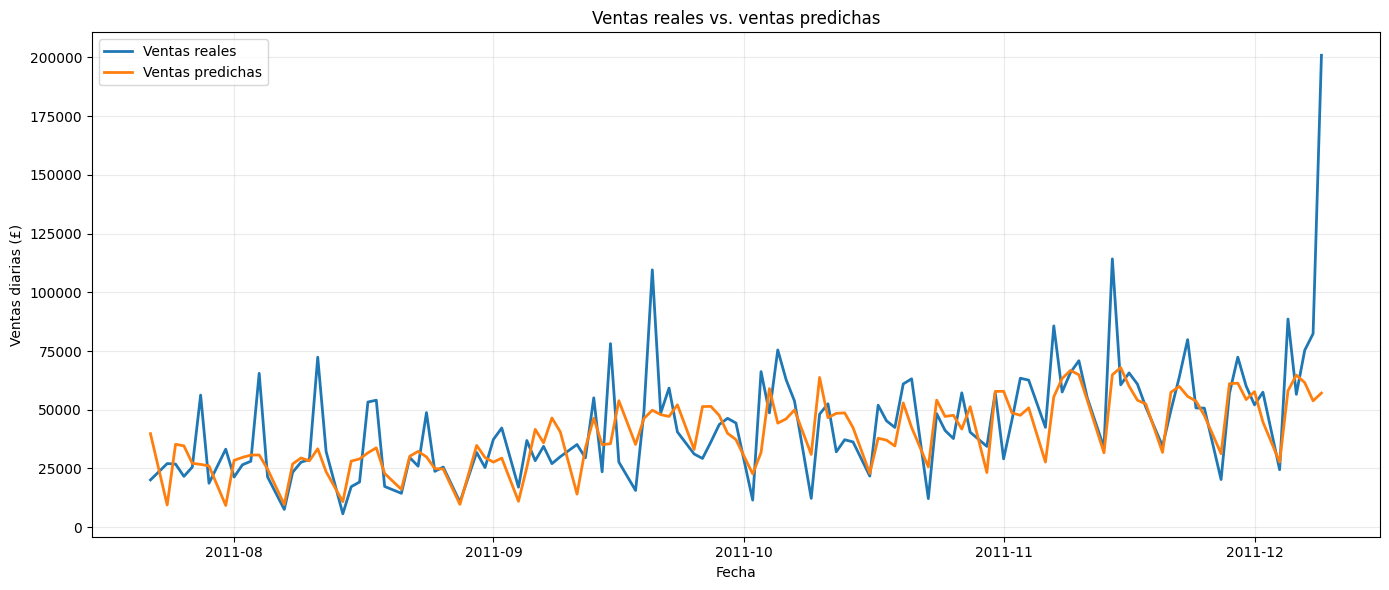

In [36]:
# ============================================================
# VENTAS REALES VS. VENTAS PREDICHAS
# ============================================================

resultados_prediccion = pd.DataFrame({
    "Fecha": fechas_test.values,
    "Venta_real": y_test.values,
    "Venta_predicha": predicciones
})

plt.figure(figsize=(14, 6))

plt.plot(
    resultados_prediccion["Fecha"],
    resultados_prediccion["Venta_real"],
    label="Ventas reales",
    linewidth=2
)

plt.plot(
    resultados_prediccion["Fecha"],
    resultados_prediccion["Venta_predicha"],
    label="Ventas predichas",
    linewidth=2
)

plt.title("Ventas reales vs. ventas predichas")
plt.xlabel("Fecha")
plt.ylabel("Ventas diarias (£)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [37]:
# ============================================================
# MODELO BASE: USAR LA VENTA ANTERIOR COMO PREDICCIÓN
# ============================================================

pred_base = X_test["Lag_1"].values

mae_base = mean_absolute_error(
    y_test,
    pred_base
)

rmse_base = mean_squared_error(
    y_test,
    pred_base
) ** 0.5

r2_base = r2_score(
    y_test,
    pred_base
)

print("=== COMPARACIÓN CON MODELO BASE ===")

print(f"Random Forest - MAE:  £{mae:,.2f}")
print(f"Modelo base   - MAE:  £{mae_base:,.2f}")

print()

print(f"Random Forest - RMSE: £{rmse:,.2f}")
print(f"Modelo base   - RMSE: £{rmse_base:,.2f}")

print()

print(f"Random Forest - R²:   {r2:.4f}")
print(f"Modelo base   - R²:   {r2_base:.4f}")

=== COMPARACIÓN CON MODELO BASE ===
Random Forest - MAE:  £12,742.03
Modelo base   - MAE:  £19,784.03

Random Forest - RMSE: £20,519.14
Modelo base   - RMSE: £27,256.99

Random Forest - R²:   0.3377
Modelo base   - R²:   -0.1687


In [38]:
# ============================================================
# MEJORA DEL MODELO:
# CREAR UNA SERIE DIARIA CONTINUA
# ============================================================

ventas_diarias_completas = (
    df
    .groupby(df["InvoiceDate"].dt.normalize())["TotalAmount"]
    .sum()
    .sort_index()
)

# Crear TODOS los días calendario del periodo
rango_fechas = pd.date_range(
    start=ventas_diarias_completas.index.min(),
    end=ventas_diarias_completas.index.max(),
    freq="D"
)

# Incorporar días sin ventas registradas
ventas_diarias_completas = (
    ventas_diarias_completas
    .reindex(rango_fechas, fill_value=0)
    .rename_axis("Fecha")
    .reset_index(name="TotalAmount")
)

print("=== SERIE DIARIA CONTINUA ===")
print(ventas_diarias_completas.head(15))

print("\nNúmero total de días calendario:")
print(len(ventas_diarias_completas))

print("\nDías con venta igual a cero:")
print(
    (ventas_diarias_completas["TotalAmount"] == 0).sum()
)

=== SERIE DIARIA CONTINUA ===
        Fecha  TotalAmount
0  2009-12-01     54351.23
1  2009-12-02     63172.58
2  2009-12-03     73972.45
3  2009-12-04     40582.32
4  2009-12-05      9803.05
5  2009-12-06     24423.02
6  2009-12-07     44916.21
7  2009-12-08     49476.23
8  2009-12-09     40265.66
9  2009-12-10     44233.96
10 2009-12-11     39447.89
11 2009-12-12         0.00
12 2009-12-13     22176.46
13 2009-12-14     73174.39
14 2009-12-15     50262.29

Número total de días calendario:
739

Días con venta igual a cero:
135


In [39]:
# ============================================================
# INGENIERÍA DE CARACTERÍSTICAS TEMPORALES
# ============================================================

ventas_mejoradas = ventas_diarias_completas.copy()

# Variables de calendario
ventas_mejoradas["Anio"] = ventas_mejoradas["Fecha"].dt.year
ventas_mejoradas["Mes"] = ventas_mejoradas["Fecha"].dt.month
ventas_mejoradas["Dia_semana"] = ventas_mejoradas["Fecha"].dt.dayofweek
ventas_mejoradas["Dia_mes"] = ventas_mejoradas["Fecha"].dt.day
ventas_mejoradas["Semana_anio"] = (
    ventas_mejoradas["Fecha"]
    .dt.isocalendar()
    .week
    .astype(int)
)

ventas_mejoradas["Trimestre"] = ventas_mejoradas["Fecha"].dt.quarter

ventas_mejoradas["Fin_semana"] = (
    ventas_mejoradas["Dia_semana"] >= 5
).astype(int)

# Rezagos reales de calendario
ventas_mejoradas["Lag_1"] = ventas_mejoradas["TotalAmount"].shift(1)
ventas_mejoradas["Lag_7"] = ventas_mejoradas["TotalAmount"].shift(7)
ventas_mejoradas["Lag_14"] = ventas_mejoradas["TotalAmount"].shift(14)
ventas_mejoradas["Lag_28"] = ventas_mejoradas["TotalAmount"].shift(28)

# Promedios móviles usando SOLO información pasada
ventas_mejoradas["Media_7"] = (
    ventas_mejoradas["TotalAmount"]
    .shift(1)
    .rolling(7)
    .mean()
)

ventas_mejoradas["Media_28"] = (
    ventas_mejoradas["TotalAmount"]
    .shift(1)
    .rolling(28)
    .mean()
)

# Variabilidad reciente
ventas_mejoradas["Std_7"] = (
    ventas_mejoradas["TotalAmount"]
    .shift(1)
    .rolling(7)
    .std()
)

# Eliminar filas iniciales sin suficientes antecedentes
ventas_mejoradas = (
    ventas_mejoradas
    .dropna()
    .reset_index(drop=True)
)

print("Registros disponibles para modelado:")
print(len(ventas_mejoradas))

print(
    ventas_mejoradas[
        [
            "Fecha",
            "TotalAmount",
            "Lag_1",
            "Lag_7",
            "Lag_14",
            "Lag_28",
            "Media_7",
            "Media_28"
        ]
    ].head()
)

Registros disponibles para modelado:
711
       Fecha  TotalAmount  Lag_1     Lag_7    Lag_14    Lag_28      Media_7  \
0 2009-12-29          0.0    0.0  28017.28  50262.29  54351.23  5552.375714   
1 2009-12-30          0.0    0.0  10849.35  52545.55  63172.58  1549.907143   
2 2009-12-31          0.0    0.0      0.00  30638.25  73972.45     0.000000   
3 2010-01-01          0.0    0.0      0.00  42470.29  40582.32     0.000000   
4 2010-01-02          0.0    0.0      0.00      0.00   9803.05     0.000000   

       Media_28  
0  29374.426786  
1  27433.311429  
2  25177.147857  
3  22535.274643  
4  21085.906071  


In [40]:
# ============================================================
# MODELO MEJORADO - DIVISIÓN TEMPORAL
# ============================================================

variables_mejoradas = [
    "Anio",
    "Mes",
    "Dia_semana",
    "Dia_mes",
    "Semana_anio",
    "Trimestre",
    "Fin_semana",
    "Lag_1",
    "Lag_7",
    "Lag_14",
    "Lag_28",
    "Media_7",
    "Media_28",
    "Std_7"
]

X_mejorado = ventas_mejoradas[variables_mejoradas]
y_mejorado = ventas_mejoradas["TotalAmount"]

# 80 % pasado = entrenamiento
# 20 % más reciente = prueba
corte_mejorado = int(len(ventas_mejoradas) * 0.80)

X_train_m = X_mejorado.iloc[:corte_mejorado]
X_test_m = X_mejorado.iloc[corte_mejorado:]

y_train_m = y_mejorado.iloc[:corte_mejorado]
y_test_m = y_mejorado.iloc[corte_mejorado:]

fechas_test_m = ventas_mejoradas["Fecha"].iloc[corte_mejorado:]

print("=== DIVISIÓN TEMPORAL MODELO MEJORADO ===")
print("Entrenamiento:", len(X_train_m), "días")
print("Prueba:", len(X_test_m), "días")

print("\nPeriodo de entrenamiento:")
print(
    ventas_mejoradas["Fecha"].iloc[0],
    "hasta",
    ventas_mejoradas["Fecha"].iloc[corte_mejorado - 1]
)

print("\nPeriodo de prueba:")
print(
    fechas_test_m.iloc[0],
    "hasta",
    fechas_test_m.iloc[-1]
)

=== DIVISIÓN TEMPORAL MODELO MEJORADO ===
Entrenamiento: 568 días
Prueba: 143 días

Periodo de entrenamiento:
2009-12-29 00:00:00 hasta 2011-07-19 00:00:00

Periodo de prueba:
2011-07-20 00:00:00 hasta 2011-12-09 00:00:00


In [41]:
# ============================================================
# RANDOM FOREST MEJORADO
# ============================================================

from sklearn.ensemble import RandomForestRegressor

modelo_ventas_mejorado = RandomForestRegressor(
    n_estimators=500,
    max_depth=12,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

modelo_ventas_mejorado.fit(
    X_train_m,
    y_train_m
)

pred_mejoradas = modelo_ventas_mejorado.predict(
    X_test_m
)

print("Modelo mejorado entrenado correctamente.")

Modelo mejorado entrenado correctamente.


In [42]:
# ============================================================
# MÉTRICAS DEL MODELO MEJORADO
# ============================================================

mae_mejorado = mean_absolute_error(
    y_test_m,
    pred_mejoradas
)

rmse_mejorado = mean_squared_error(
    y_test_m,
    pred_mejoradas
) ** 0.5

r2_mejorado = r2_score(
    y_test_m,
    pred_mejoradas
)

print("=== RESULTADOS MODELO MEJORADO ===")

print(f"MAE:  £{mae_mejorado:,.2f}")
print(f"RMSE: £{rmse_mejorado:,.2f}")
print(f"R²:   {r2_mejorado:.4f}")

=== RESULTADOS MODELO MEJORADO ===
MAE:  £10,809.01
RMSE: £18,934.37
R²:   0.5409


In [43]:
# ============================================================
# BASELINES TEMPORALES
# ============================================================

# Predicción = venta del día anterior
pred_base_1 = X_test_m["Lag_1"].values

# Predicción = venta del mismo día de la semana anterior
pred_base_7 = X_test_m["Lag_7"].values

mae_base_1 = mean_absolute_error(y_test_m, pred_base_1)
rmse_base_1 = mean_squared_error(y_test_m, pred_base_1) ** 0.5
r2_base_1 = r2_score(y_test_m, pred_base_1)

mae_base_7 = mean_absolute_error(y_test_m, pred_base_7)
rmse_base_7 = mean_squared_error(y_test_m, pred_base_7) ** 0.5
r2_base_7 = r2_score(y_test_m, pred_base_7)

comparacion_prediccion = pd.DataFrame({
    "Modelo": [
        "Random Forest mejorado",
        "Base Lag 1",
        "Base Lag 7"
    ],
    "MAE": [
        mae_mejorado,
        mae_base_1,
        mae_base_7
    ],
    "RMSE": [
        rmse_mejorado,
        rmse_base_1,
        rmse_base_7
    ],
    "R2": [
        r2_mejorado,
        r2_base_1,
        r2_base_7
    ]
})

print("=== COMPARACIÓN DE MODELOS ===")

print(
    comparacion_prediccion
    .round(2)
    .to_string(index=False)
)

=== COMPARACIÓN DE MODELOS ===
                Modelo      MAE     RMSE    R2
Random Forest mejorado 10809.01 18934.37  0.54
            Base Lag 1 22731.46 29781.78 -0.14
            Base Lag 7 13169.22 21395.86  0.41


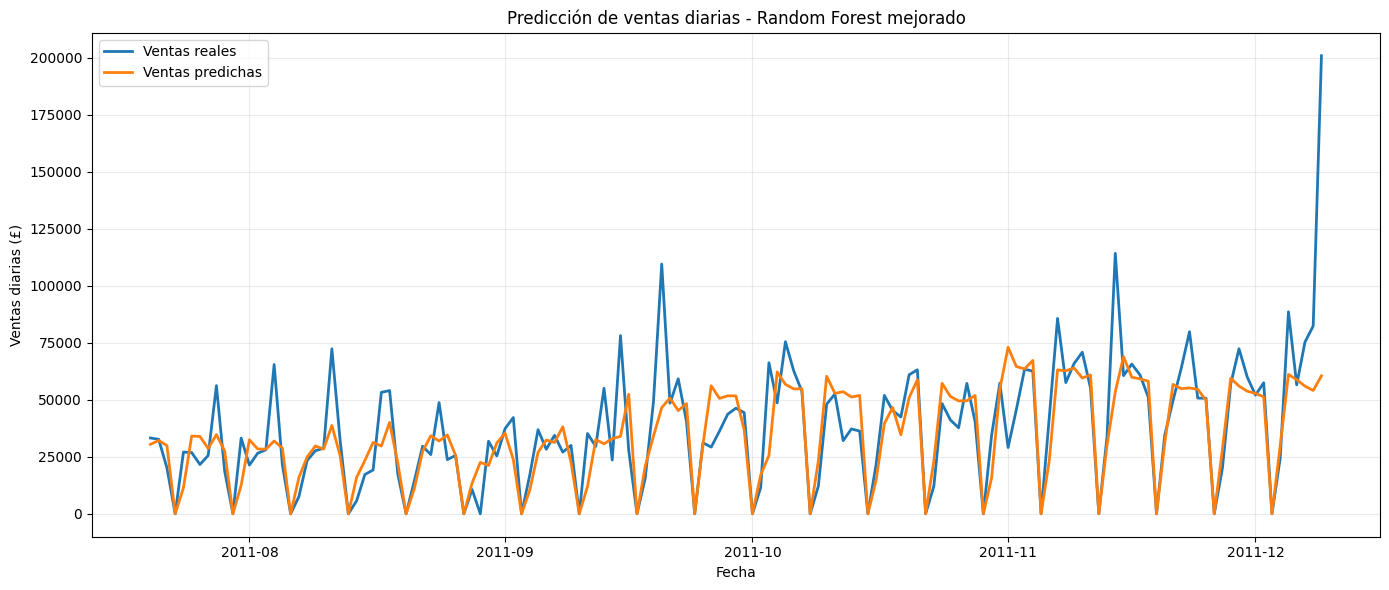

In [44]:
# ============================================================
# GRÁFICA FINAL: VENTAS REALES VS. PREDICHAS
# ============================================================

resultado_final = pd.DataFrame({
    "Fecha": fechas_test_m.values,
    "Venta_real": y_test_m.values,
    "Venta_predicha": pred_mejoradas
})

plt.figure(figsize=(14, 6))

plt.plot(
    resultado_final["Fecha"],
    resultado_final["Venta_real"],
    label="Ventas reales",
    linewidth=2
)

plt.plot(
    resultado_final["Fecha"],
    resultado_final["Venta_predicha"],
    label="Ventas predichas",
    linewidth=2
)

plt.title(
    "Predicción de ventas diarias - Random Forest mejorado"
)

plt.xlabel("Fecha")
plt.ylabel("Ventas diarias (£)")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [45]:
# ============================================================
# IMPORTANCIA DE VARIABLES DEL MODELO
# ============================================================

importancia_prediccion = pd.DataFrame({
    "Variable": variables_mejoradas,
    "Importancia": modelo_ventas_mejorado.feature_importances_
}).sort_values(
    "Importancia",
    ascending=False
)

print("=== IMPORTANCIA DE VARIABLES ===")
print(
    importancia_prediccion
    .round(4)
    .to_string(index=False)
)

=== IMPORTANCIA DE VARIABLES ===
   Variable  Importancia
    Media_7       0.2238
      Lag_7       0.1699
 Fin_semana       0.1556
 Dia_semana       0.1325
      Lag_1       0.0818
     Lag_28       0.0521
   Media_28       0.0388
      Std_7       0.0351
Semana_anio       0.0344
     Lag_14       0.0344
    Dia_mes       0.0284
        Mes       0.0072
       Anio       0.0045
  Trimestre       0.0013
